CÁLCULO DE DOSE DE RX PARA PEROVSKITA

gerador de rx em 50kV e alvo de tungstenio

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
#parametros do gerador
V_kV = 50          # tensão em kV
Z = 74             # tungstênio (W)

#coeficiente de absorção massica para CsPbBr3 (varia com energia)
mu_rho = 6       # m²/kg

#tempo de exposição (s)
tempo_exp = 30


#corrente e distancia experimentais
correntes_uA = [20,60,100,140]

distancias_cm = [5,20]
 
#calculo da dose considerando um único patamar de 30s de gerador ligado
V = V_kV * 1e3

resultados = []

for corrente_uA in correntes_uA:

    I = corrente_uA * 1e-6  #conversao para A

    for d_cm in distancias_cm:

        r = d_cm / 100  #conversao para m

        #taxa de dose
        dose_rate = (
            (9e-7 * I * V**2 * Z) /
            (np.pi * r**2)
        ) * mu_rho

        #dose total
        dose_total = dose_rate * (tempo_exp / 3600)

        resultados.append([
            corrente_uA,
            d_cm,
            dose_rate,
            dose_total
        ])

df = pd.DataFrame(
    resultados,
    columns=[
        "Corrente (uA)",
        "Distância (cm)",
        "Taxa de dose (Gy/h)",
        "Dose total (Gy)"
    ]
)

print(df)

# salvar em csv
#df.to_csv(
#    r"C:/Users/julia.fukunaga/Documents/dose_si.csv", 
#    sep=";",
#    decimal=",",
#    index=False)


   Corrente (uA)  Distância (cm)  Taxa de dose (Gy/h)  Dose total (Gy)
0             20               5          2543.932610        21.199438
1             20              20           158.995788         1.324965
2             60               5          7631.797831        63.598315
3             60              20           476.987364         3.974895
4            100               5         12719.663052       105.997192
5            100              20           794.978941         6.624825
6            140               5         17807.528273       148.396069
7            140              20          1112.970517         9.274754


In [8]:
#cálculo da dose acumulada para toda a medida

#somando os patamares de uma mesma corrente

tempo_acum = 30*3
resultados_sum = []

for corrente_uA in correntes_uA:

    I = corrente_uA * 1e-6  #conversao para A

    for d_cm in distancias_cm:

        r = d_cm / 100  #conversao para m

        #taxa de dose
        dose_rate = (
            (9e-7 * I * V**2 * Z) /
            (np.pi * r**2)
        ) * mu_rho

        #dose total
        dose_total = dose_rate * (tempo_acum / 3600)
 

        resultados_sum.append([
            corrente_uA,
            d_cm,
            dose_rate,
            dose_total
        ])

df_sum = pd.DataFrame(
    resultados_sum,
    columns=[
        "Corrente (uA)",
        "Distância (cm)",
        "Taxa de dose (Gy/h)",
        "Dose total (Gy)"
    ]
)

print(df_sum)

#salvar em csv
#df_sum.to_csv(
#    r"C:/Users/julia.fukunaga/Documents/dose2_perov.csv", 
#    sep=";",
#    decimal=",",
#    index=False)

   Corrente (uA)  Distância (cm)  Taxa de dose (Gy/h)  Dose total (Gy)
0             20               5          2543.932610        63.598315
1             20              20           158.995788         3.974895
2             60               5          7631.797831       190.794946
3             60              20           476.987364        11.924684
4            100               5         12719.663052       317.991576
5            100              20           794.978941        19.874474
6            140               5         17807.528273       445.188207
7            140              20          1112.970517        27.824263


In [9]:
#somando as doses com a variação de corrente

resultados_acum = []

indices_1 = [0,2,4,6]
indices_2 = [1,3,5,7]

dose_selec_1 = [resultados_sum[i][3] for i in indices_1]  #selecionando a dose total
dose_selec_2 = [resultados_sum[i][3] for i in indices_2]

dose_acum_1 = sum(dose_selec_1)
dose_acum_2 = sum(dose_selec_2)

print("doses selecionadas em 5 cm:", dose_selec_1)
print("dose acumulada:", dose_acum_1)
print()
print("doses selecionadas em 20 cm:", dose_selec_2)
print("dose acumulada:", dose_acum_2)

resultados_acum.append([
    dose_acum_1,
    dose_acum_2
])


df_acum = pd.DataFrame(
    resultados_acum,
    columns=[
        "Dose Acumulada em 5cm (Gy)",
        "Dose Acumulada em 20cm (Gy)"
    ]
)
print()
print(df_acum)

doses selecionadas em 5 cm: [63.598315259521364, 190.79494577856408, 317.99157629760685, 445.1882068166495]
dose acumulada: 1017.5730441523418

doses selecionadas em 20 cm: [3.9748947037200852, 11.924684111160255, 19.87447351860043, 27.824262926040593]
dose acumulada: 63.598315259521364

   Dose Acumulada em 5cm (Gy)  Dose Acumulada em 20cm (Gy)
0                 1017.573044                    63.598315


In [5]:
#propagação de incertezas da estimativa de dose

erro_corrente = 0.003
erro_tensao = 0.001

distancias = np.array(distancias_cm)
erro_distancia = 0.5/distancias

incerteza = np.sqrt(erro_corrente**2 + 4*erro_tensao**2 + 4*erro_distancia**2)
    
print(incerteza)
print(erro_distancia)

[0.2000325  0.05012983]
[0.1   0.025]


In [12]:
#calculo da incerteza por medida

dose_total_lista = [linha[3] for linha in resultados_sum]

x = 0.2000325
y = 0.05012983

erro_medidas = [
    valor * x if i % 2 == 0 else valor * y
    for i, valor in enumerate(dose_total_lista)
]

print(erro_medidas)

[12.721729997150208, 0.19926079576538824, 38.16518999145062, 0.5977823872961647, 63.60864998575104, 0.9963039788269413, 89.05210998005144, 1.3948255703577175]


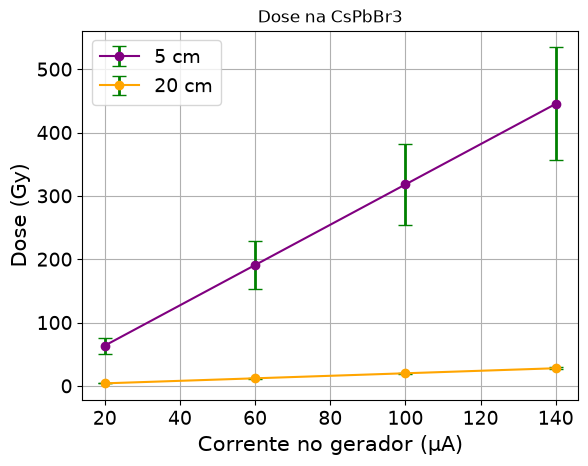

In [20]:
#grafico da dose com barra de erro

distancias = sorted(set([linha[1] for linha in resultados_sum]))

erro_5cm = erro_medidas[::2]   # 0,2,4,6
erro_20cm = erro_medidas[1::2] # 1,3,5,7

cor = ['purple','orange']
for i, d in enumerate(distancias):

    corrente = [linha[0] for linha in resultados_sum
                if linha[1] == d]

    dose = [linha[3] for linha in resultados_sum
            if linha[1] == d]
    if d == 5:
        yerr = erro_5cm
    else:
        yerr = erro_20cm


    plt.errorbar(
    corrente,
    dose,
    yerr=yerr,
    fmt='o-',
    color=cor[i],
    ecolor='green',
    capsize=5,
    elinewidth=2,
    label=f'{d} cm'
)

plt.ylabel('Dose (Gy)', fontsize=15)
plt.xlabel('Corrente no gerador (µA)',fontsize=15)
plt.legend(fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.title('Dose na CsPbBr3')
plt.grid(True)

plt.savefig(
    r"C:\Users\julia.fukunaga\Documents\dose_CsPbBr3_plot_erros.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

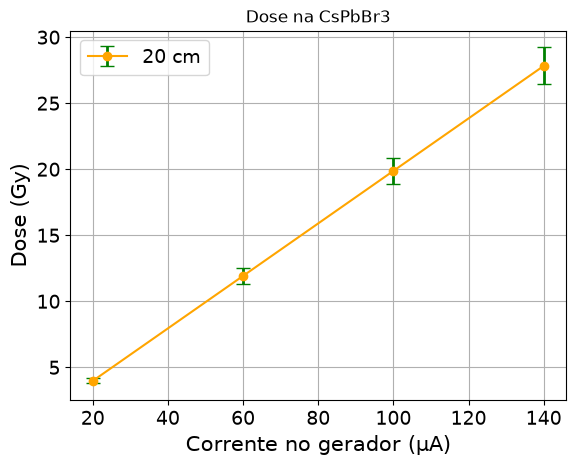

In [17]:
#plot apenas de 20 cm para visualizar melhor o eixo y


plt.errorbar(
    correntes_uA,
    dose_selec_2,
    yerr=erro_20cm,
    fmt='o-',
    color='orange',
    ecolor='green',
    capsize=5,
    elinewidth=2,
    label= '20 cm'
)

plt.ylabel('Dose (Gy)', fontsize=15)
plt.xlabel('Corrente no gerador (µA)',fontsize=15)
plt.legend(fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.title('Dose na CsPbBr3')
plt.grid(True)

plt.savefig(
    r"C:\Users\julia.fukunaga\Documents\Experimento Mobi Perov Pips\dose_CsPbBr3_20cm.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
    